In [1]:
# ==========================================================
# WEEK 2 MASTER CHEAT SHEET
# ==========================================================

cheat_sheet = """
╔══════════════════════════════════════════════════════════════════════╗
║          WEEK 2 CHEAT SHEET: SQL, PANDAS & DATA PIPELINES          ║
╠══════════════════════════════════════════════════════════════════════╣
║                                                                      ║
║  ── SQL BASICS ──────────────────────────────────────────────────     ║
║  SELECT col1, col2     → Pick which columns to show                  ║
║  FROM table_name       → Which table to pull from                    ║
║  WHERE condition       → Filter rows (e.g., grade > 50)              ║
║  GROUP BY col          → Summarize by category                       ║
║  ORDER BY col DESC     → Sort highest to lowest                      ║
║  JOIN table ON a.id=b.id → Connect two tables by shared ID           ║
║  LEFT JOIN             → Keep ALL rows from left table               ║
║  COUNT(), AVG(), MAX() → Aggregate calculations                      ║
║                                                                      ║
║  ── PANDAS EQUIVALENTS ─────────────────────────────────────────     ║
║  SQL: WHERE grade > 50                                                ║
║  PD:  df[df['grade'] > 50]                                           ║
║                                                                      ║
║  SQL: GROUP BY class + AVG(grade)                                     ║
║  PD:  df.groupby('class')['grade'].mean()                             ║
║                                                                      ║
║  SQL: JOIN table ON id = id                                           ║
║  PD:  pd.merge(df1, df2, on='id', how='inner')                       ║
║                                                                      ║
║  SQL: ORDER BY grade DESC                                             ║
║  PD:  df.sort_values('grade', ascending=False)                        ║
║                                                                      ║
║  ── DATA CLEANING ──────────────────────────────────────────────      ║
║  .str.strip()          → Remove leading/trailing spaces               ║
║  .str.upper()          → Convert to UPPERCASE                         ║
║  .str.lower()          → Convert to lowercase                         ║
║  .str.title()          → Convert to Title Case                        ║
║  pd.to_numeric(errors='coerce') → Convert text to numbers safely      ║
║  .fillna(value)        → Replace missing NaN values                   ║
║  .drop_duplicates()    → Remove duplicate rows                        ║
║                                                                      ║
║  ── DATE & TIME ────────────────────────────────────────────────      ║
║  pd.to_datetime(col)   → Convert text to real dates                   ║
║  .dt.hour              → Extract hour (0-23)                          ║
║  .dt.day_name()        → Extract 'Monday', 'Tuesday', etc.            ║
║  .dt.days              → Extract number of days from time difference  ║
║  (date1 - date2).dt.days → Calculate days between two dates           ║
║                                                                      ║
║  ── PIPELINE PATTERN ──────────────────────────────────────────       ║
║  1. EXTRACT   → Pull raw data (SQL query or pd.read_csv)              ║
║  2. CLEAN     → Fix text, types, missing values, duplicates           ║
║  3. TRANSFORM → Calculate new columns, apply business logic           ║
║  4. EXPORT    → Save results (.to_csv with timestamp)                 ║
║                                                                      ║
╚══════════════════════════════════════════════════════════════════════╝
"""
print(cheat_sheet)


╔══════════════════════════════════════════════════════════════════════╗
║          WEEK 2 CHEAT SHEET: SQL, PANDAS & DATA PIPELINES          ║
╠══════════════════════════════════════════════════════════════════════╣
║                                                                      ║
║  ── SQL BASICS ──────────────────────────────────────────────────     ║
║  SELECT col1, col2     → Pick which columns to show                  ║
║  FROM table_name       → Which table to pull from                    ║
║  WHERE condition       → Filter rows (e.g., grade > 50)              ║
║  GROUP BY col          → Summarize by category                       ║
║  ORDER BY col DESC     → Sort highest to lowest                      ║
║  JOIN table ON a.id=b.id → Connect two tables by shared ID           ║
║  LEFT JOIN             → Keep ALL rows from left table               ║
║  COUNT(), AVG(), MAX() → Aggregate calculations                      ║
║                                                  

In [2]:
# ==========================================================
# CONSOLIDATION CHALLENGE: FULL PIPELINE FROM SCRATCH
# ==========================================================

import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

sns.set_style("whitegrid")

# 1. Create a fresh database
conn2 = sqlite3.connect('consolidation_challenge.db')
cursor2 = conn2.cursor()

# 2. Create tables
cursor2.execute('CREATE TABLE IF NOT EXISTS students (sid TEXT, name TEXT, email TEXT)')
cursor2.execute('CREATE TABLE IF NOT EXISTS courses (cid TEXT, cname TEXT, dept TEXT)')
cursor2.execute('CREATE TABLE IF NOT EXISTS grades (gid INTEGER, sid TEXT, cid TEXT, score TEXT)')
cursor2.execute('CREATE TABLE IF NOT EXISTS logins (lid INTEGER, sid TEXT, login_date TEXT)')

# 3. Insert DIRTY data (realistic mess!)
cursor2.executemany('INSERT OR IGNORE INTO students VALUES (?,?,?)', [
    ('S1', '  AMINA OKAFOR ', 'AMINA@UNI.EDU'),
    ('S2', 'james smith', 'james@uni.edu'),
    ('S3', 'Fatima Bello', 'fatima@uni.edu'),
    ('S4', 'DAVID CHEN ', 'david@uni.edu'),
    ('S5', 'grace eze', 'grace@uni.edu')
])

cursor2.executemany('INSERT OR IGNORE INTO courses VALUES (?,?,?)', [
    ('C1', 'python basics', 'cs'),
    ('C2', 'calculus i', 'math'),
    ('C3', 'edtech systems', 'education')
])

cursor2.executemany('INSERT OR IGNORE INTO grades VALUES (?,?,?,?)', [
    (1, 'S1', 'C1', '92.5%'),
    (2, 'S2', 'C2', '38.0%'),    # Failing
    (3, 'S3', 'C1', '85.0%'),
    (4, 'S4', 'C3', 'ABSENT'),   # Corrupted!
    (5, 'S5', 'C2', '47.0%')     # Failing
])

cursor2.executemany('INSERT OR IGNORE INTO logins VALUES (?,?,?)', [
    (1, 'S1', '2026-09-14'),  # Active today
    (2, 'S2', '2026-09-01'),  # Inactive 13 days!
    (3, 'S3', '2026-09-13'),  # Active yesterday
    (4, 'S4', '2026-09-08'),  # Inactive 6 days
    (5, 'S5', '2026-09-03')   # Inactive 11 days!
])

conn2.commit()
print("✅ Dirty database created with 5 students, 3 courses, and messy data!")

✅ Dirty database created with 5 students, 3 courses, and messy data!


--- STAGE 1: RAW EXTRACTED DATA ---
  sid             name           email           cname       dept   score
0  S1    AMINA OKAFOR    AMINA@UNI.EDU   python basics         cs   92.5%
1  S2      james smith   james@uni.edu      calculus i       math   38.0%
2  S3     Fatima Bello  fatima@uni.edu   python basics         cs   85.0%
3  S4      DAVID CHEN    david@uni.edu  edtech systems  education  ABSENT
4  S5        grace eze   grace@uni.edu      calculus i       math   47.0%

--- STAGE 2: CLEANED DATA ---
           name           email           cname       dept  numeric_score
0  Amina Okafor   amina@uni.edu   Python Basics         CS           92.5
1   James Smith   james@uni.edu      Calculus I       MATH           38.0
2  Fatima Bello  fatima@uni.edu   Python Basics         CS           85.0
3    David Chen   david@uni.edu  Edtech Systems  EDUCATION           65.6
4     Grace Eze   grace@uni.edu      Calculus I       MATH           47.0

--- STAGE 3: WITH INACTIVITY DATA ---
      

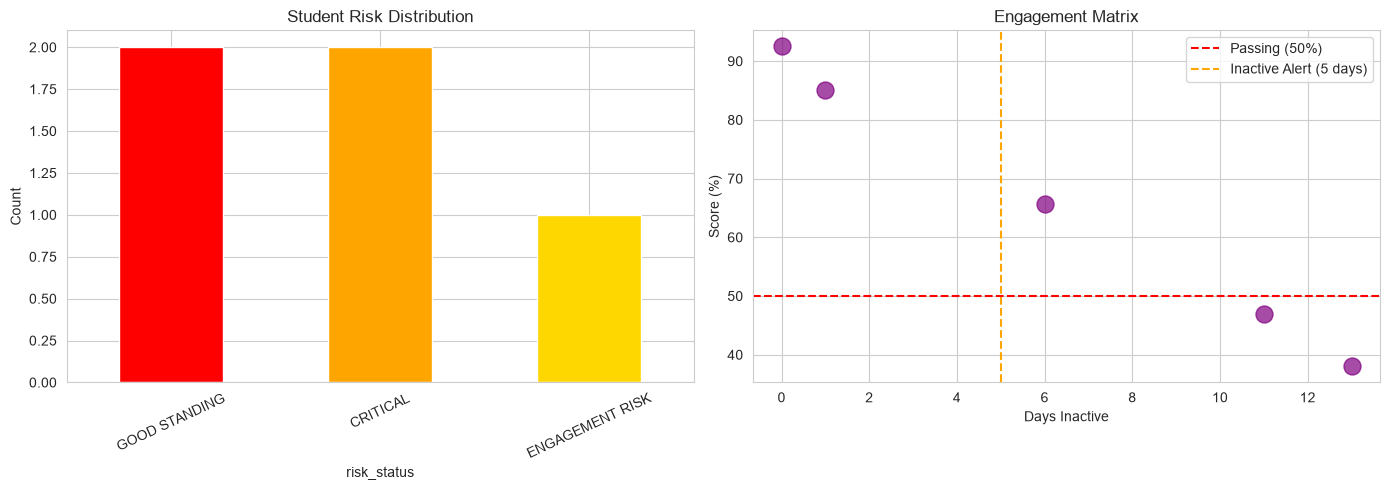


--- STAGE 6: REPORT EXPORTED ---
File: Week2_Consolidation_Report_2026-10-16.csv
Students flagged: 3
          name  numeric_score  days_inactive      risk_status
1  James Smith           38.0             13         CRITICAL
3   David Chen           65.6              6  ENGAGEMENT RISK
4    Grace Eze           47.0             11         CRITICAL


In [3]:
# ==========================================================
# THE FULL PIPELINE (Read each comment carefully!)
# ==========================================================

# --- STAGE 1: EXTRACT via SQL JOIN ---
# Connect all 3 tables: students + courses + grades
extract_query = """
    SELECT 
        s.sid,
        s.name,
        s.email,
        c.cname,
        c.dept,
        g.score
    FROM grades g
    JOIN students s ON g.sid = s.sid
    JOIN courses c ON g.cid = c.cid
"""

df = pd.read_sql_query(extract_query, conn2)
print("--- STAGE 1: RAW EXTRACTED DATA ---")
print(df)


# --- STAGE 2: CLEAN ---
# Fix messy names: strip spaces + title case
df['name'] = df['name'].str.strip().str.title()

# Fix messy emails: lowercase
df['email'] = df['email'].str.strip().str.lower()

# Fix messy course names: title case
df['cname'] = df['cname'].str.strip().str.title()

# Fix messy department codes: uppercase
df['dept'] = df['dept'].str.strip().str.upper()

# Fix corrupted scores: remove '%', convert 'ABSENT' to NaN
clean_scores = df['score'].str.replace('%', '', regex=False)
df['numeric_score'] = pd.to_numeric(clean_scores, errors='coerce')

# Fill missing scores with class average
class_avg = df['numeric_score'].mean()
df['numeric_score'] = df['numeric_score'].fillna(class_avg).round(1)

print("\n--- STAGE 2: CLEANED DATA ---")
print(df[['name', 'email', 'cname', 'dept', 'numeric_score']])


# --- STAGE 3: ADD INACTIVITY DATA ---
# Pull login data and calculate days inactive
df_logins = pd.read_sql_query("SELECT * FROM logins", conn2)
df_logins['login_date'] = pd.to_datetime(df_logins['login_date'])

# Find latest login per student
latest_logins = df_logins.groupby('sid')['login_date'].max().reset_index()
latest_logins.columns = ['sid', 'last_login']

# Merge with main dataset
df = pd.merge(df, latest_logins, on='sid', how='left')

# Calculate days inactive
today = pd.to_datetime('2026-09-14')
df['days_inactive'] = (today - df['last_login']).dt.days

print("\n--- STAGE 3: WITH INACTIVITY DATA ---")
print(df[['name', 'numeric_score', 'days_inactive']])


# --- STAGE 4: RISK FLAGGING ---
def assign_risk(row):
    failing = row['numeric_score'] < 50
    inactive = row['days_inactive'] >= 5
    
    if failing and inactive:
        return 'CRITICAL'
    elif failing:
        return 'ACADEMIC RISK'
    elif inactive:
        return 'ENGAGEMENT RISK'
    else:
        return 'GOOD STANDING'

df['risk_status'] = df.apply(assign_risk, axis=1)

print("\n--- STAGE 4: RISK ASSESSMENT ---")
print(df[['name', 'numeric_score', 'days_inactive', 'risk_status']])


# --- STAGE 5: VISUALIZE ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Risk Distribution
df['risk_status'].value_counts().plot(kind='bar', ax=axes[0], color=['red', 'orange', 'gold', 'green'])
axes[0].set_title('Student Risk Distribution')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=25)

# Chart 2: Score vs Inactivity Scatter
axes[1].scatter(df['days_inactive'], df['numeric_score'], s=150, color='purple', alpha=0.7)
axes[1].axhline(50, color='red', linestyle='--', label='Passing (50%)')
axes[1].axvline(5, color='orange', linestyle='--', label='Inactive Alert (5 days)')
axes[1].set_title('Engagement Matrix')
axes[1].set_xlabel('Days Inactive')
axes[1].set_ylabel('Score (%)')
axes[1].legend()

plt.tight_layout()
plt.show()


# --- STAGE 6: EXPORT ---
date_stamp = datetime.date.today().strftime('%Y-%m-%d')
at_risk = df[df['risk_status'] != 'GOOD STANDING']
filename = f"Week2_Consolidation_Report_{date_stamp}.csv"
at_risk[['name', 'email', 'cname', 'numeric_score', 'days_inactive', 'risk_status']].to_csv(filename, index=False)

print(f"\n--- STAGE 6: REPORT EXPORTED ---")
print(f"File: {filename}")
print(f"Students flagged: {len(at_risk)}")
print(at_risk[['name', 'numeric_score', 'days_inactive', 'risk_status']])